# 🧬 Predizione della Bioattività di Molecole Prodotte dalle Piante

## Laboratorio di Intelligenza Artificiale - Università degli Studi di Parma

### Obiettivo
Sviluppare modelli di machine learning per predire la **bioattività** di molecole derivate da piante, utilizzando:
- **Embedding degli spettri di massa** (Spec2Vec, 500 features)
- **Embedding delle proteine target** (UniRep, 3 dimensionalità: 64, 256, 1900)

### Struttura del Notebook
1. Configurazione ambiente e importazione librerie
2. Caricamento ed esplorazione del dataset
3. Definizione del target (classificazione binaria)
4. Merge dei dataset
5. Preprocessing e feature engineering
6. Definizione dei modelli (RF, XGBoost, Neural Network)
7. Training e valutazione
8. Confronto dei risultati
9. Feature importance analysis
10. Cross-validation
11. Salvataggio modelli
12. Conclusioni

---

In [1]:
# ===============================================================================
# PREDIZIONE DELLA BIOATTIVITÀ DI MOLECOLE PRODOTTE DALLE PIANTE
# ===============================================================================
# Corso: Laboratorio di Intelligenza Artificiale
# Università degli Studi di Parma
# 
# Obiettivo: Sviluppare modelli di machine learning per predire la bioattività
# di molecole a partire da embedding di spettri di massa e proteine target.
#
# Dataset:
# - Bioactivities: interazioni molecola-proteina con valori pChEMBL
# - Mass Spectra Embeddings: embedding Spec2Vec delle molecole (500 features)
# - Protein Embeddings: embedding UniRep delle proteine (3 dimensionalità)
# ===============================================================================

# Configurazione per rilevamento GPU (Colab/HPC)
import warnings
warnings.filterwarnings('ignore')

# Verifica disponibilità GPU
import torch
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA disponibile: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Numero di GPU: {torch.cuda.device_count()}")
    DEVICE = torch.device("cuda")
else:
    print("Utilizzo CPU")
    DEVICE = torch.device("cpu")

PyTorch version: 2.7.0+cpu
CUDA disponibile: False
Utilizzo CPU


In [2]:
# ===============================================================================
# 1. IMPORTAZIONE LIBRERIE
# ===============================================================================

# Data manipulation
import pandas as pd
import numpy as np
from pathlib import Path

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer

# Models
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
import xgboost as xgb

# Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score
)

# Deep Learning (PyTorch)
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# Utilities
from tqdm import tqdm
import time
from collections import Counter

# Set random seeds for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

# Plot style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

print("✅ Librerie importate correttamente!")

✅ Librerie importate correttamente!


## 2. Caricamento e Esplorazione del Dataset

Il dataset è composto da tre componenti principali:
1. **Bioactivities**: contiene le interazioni molecola-proteina con valori di bioattività (pChEMBL)
2. **Mass Spectra Embeddings**: embedding delle molecole ottenuti con Spec2Vec (500 features)
3. **Protein Embeddings**: embedding delle proteine ottenuti con UniRep (3 dimensionalità: 64, 256, 1900)

In [4]:
# ===============================================================================
# 2. CARICAMENTO DEL DATASET
# ===============================================================================

# Percorso base del dataset (modificare se necessario per Colab)
# Per Google Colab: montare prima il drive e modificare il path
# from google.colab import drive
# drive.mount('/content/drive')
# BASE_PATH = Path('/content/drive/MyDrive/dataset_bioactivities')

# Per esecuzione locale
BASE_PATH = Path('dataset_bioactivities')

# Caricamento bioactivities
print("📊 Caricamento dataset bioactivities...")
df_bioactivities = pd.read_csv(BASE_PATH / 'bioactivities' / 'dataset_bioactivities_negative.csv')

# Caricamento molecule embeddings
print("📊 Caricamento molecule embeddings...")
df_molecules = pd.read_csv(BASE_PATH / 'mass_spectra_embeddings' / 'ALL_GNPS_negative_ionization_DATASET.csv')

# Caricamento protein embeddings (3 dimensionalità)
print("📊 Caricamento protein embeddings...")
df_proteins_64 = pd.read_csv(BASE_PATH / 'protein_embeddings' / 'protein_embeddings_UniRep64.csv')
df_proteins_256 = pd.read_csv(BASE_PATH / 'protein_embeddings' / 'protein_embeddings_UniRep256.csv')
df_proteins_1900 = pd.read_csv(BASE_PATH / 'protein_embeddings' / 'protein_embeddings_UniRep1900.csv')

print(f"\n✅ Dataset caricati con successo!")
print(f"   - Bioactivities: {df_bioactivities.shape}")
print(f"   - Molecule Mass Spectra: {df_molecules.shape}")
print(f"   - Protein UniRep64: {df_proteins_64.shape}")
print(f"   - Protein UniRep256: {df_proteins_256.shape}")
print(f"   - Protein UniRep1900: {df_proteins_1900.shape}")

📊 Caricamento dataset bioactivities...
📊 Caricamento molecule embeddings...
📊 Caricamento protein embeddings...

✅ Dataset caricati con successo!
   - Bioactivities: (10092, 36)
   - Molecule Mass Spectra: (5798, 507)
   - Protein UniRep64: (1142, 193)
   - Protein UniRep256: (1142, 769)
   - Protein UniRep1900: (1142, 5701)


In [ ]:
df_bioactivities

In [ ]:
df_molecules

In [ ]:
df_proteins_64

Rimuovo le colonne contenenti metadati non utili (se ci fosse stato qualche 1 in ms_level poteva aver senso filtrare e tenere solo i 2 ma sono tutti 2)

In [ ]:
dfc_molecules = df_molecules.copy()
dfc_molecules.drop(columns=['backbone_inchikey', 'spectrum_id', 'smiles', 'inchi', 'instrument', 'ms_level'], inplace=True)

Capire se fare la media degli embedding raggruppando per inchikey.

Sicuramente andranno poi ridotte le colonne con una pca o simili.

potrebbe aver senso droppare proprio i dati borderline (tra 5 e 6) se non sono troppi 

# modelli da confrontare

- LDA + random forest 
- LDA + xgboost 
- NN 

# modello usato da maresi (pdf)

- PCA + xgboost

In [40]:
# guardo le deviazioni standard delle features raggruppate per inchikey
dfc_molecules_std = dfc_molecules.groupby('inchikey').std()
dfc_molecules_std


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120,121,122,123,124,125,126,127,128,129,130,131,132,133,134,135,136,137,138,139,140,141,142,143,144,145,146,147,148,149,150,151,152,153,154,155,156,157,158,159,160,161,162,163,164,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,193,194,195,196,197,198,199,200,201,202,203,204,205,206,207,208,209,210,211,212,213,214,215,216,217,218,219,220,221,222,223,224,225,226,227,228,229,230,231,232,233,234,235,236,237,238,239,240,241,242,243,244,245,246,247,248,249,250,251,252,253,254,255,256,257,258,259,260,261,262,263,264,265,266,267,268,269,270,271,272,273,274,275,276,277,278,279,280,281,282,283,284,285,286,287,288,289,290,291,292,293,294,295,296,297,298,299,300,301,302,303,304,305,306,307,308,309,310,311,312,313,314,315,316,317,318,319,320,321,322,323,324,325,326,327,328,329,330,331,332,333,334,335,336,337,338,339,340,341,342,343,344,345,346,347,348,349,350,351,352,353,354,355,356,357,358,359,360,361,362,363,364,365,366,367,368,369,370,371,372,373,374,375,376,377,378,379,380,381,382,383,384,385,386,387,388,389,390,391,392,393,394,395,396,397,398,399,400,401,402,403,404,405,406,407,408,409,410,411,412,413,414,415,416,417,418,419,420,421,422,423,424,425,426,427,428,429,430,431,432,433,434,435,436,437,438,439,440,441,442,443,444,445,446,447,448,449,450,451,452,453,454,455,456,457,458,459,460,461,462,463,464,465,466,467,468,469,470,471,472,473,474,475,476,477,478,479,480,481,482,483,484,485,486,487,488,489,490,491,492,493,494,495,496,497,498,499
inchikey,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
AAKJLRGGTJKAMG-UHFFFAOYSA-N,6.245247,6.519279,5.934610,4.540856,6.620523,2.489483,4.381078,3.615169,3.109058,3.660529,4.451940,5.745883,7.559962,4.072365,6.476132,2.762566,5.559808,5.298071,4.471965,5.433236,2.821211,5.248882,8.598880,3.000066,3.317040,4.544859,3.507447,7.236271,4.791240,5.801438,1.887501,5.301551,5.565051,2.983124,4.779495,7.720690,6.894780,3.291625,4.337847,5.250978,8.326598,5.023936,4.167488,3.673592,3.883446,4.454034,7.420617,5.938713,2.362372,4.903486,5.173638,7.085118,3.828226,5.884381,3.647579,1.985799,7.400339,3.819605,8.724922,4.069016,2.324248,7.068235,5.583627,3.433223,6.720887,5.593629,13.330762,2.576635,3.874636,2.828036,1.964641,4.809433,3.541902,4.285640,11.853618,2.445744,3.543682,5.071759,6.108277,2.740030,3.747463,3.332383,4.184660,3.375543,1.473818,3.566706,4.922288,3.834802,2.777451,3.641698,2.190015,5.344883,3.627319,3.441393,7.160561,3.780149,5.795002,5.117981,3.116871,3.133475,9.119175,3.137550,2.901723,4.113330,4.926637,2.375998,8.510843,4.103376,4.599676,2.929272,4.399861,2.827019,4.099470,3.751990,7.332543,8.570676,4.515918,4.370002,5.528323,4.463937,8.949697,4.270883,5.183964,2.365579,2.440770,5.293023,3.005298,4.836753,4.409059,4.871914,8.967565,3.337286,4.238609,4.372762,4.126597,2.543023,2.406299,6.835798,3.549907,5.096826,3.309720,3.044159,5.965909,6.098861,5.383633,9.220648,3.889325,6.023070,5.211509,2.271914,8.556606,7.892395,6.524756,4.193706,6.176950,4.839880,2.771266,3.548271,3.720601,7.147171,4.075418,2.660119,1.847140,4.171321,4.480091,6.582717,4.345963,2.363816,6.724311,4.670910,3.863274,4.679483,2.626475,4.646948,4.39

Potrebbe aver senso rimuovere quelle molecole che hanno dev std troppo alta (se > 15 se ne toglierebbero 12 su 714)

In [41]:
# guardo la media delle deviazioni standard delle features raggruppate per inchikey
dfc_molecules_std = dfc_molecules.groupby('inchikey').std().mean(axis=1)
dfc_molecules_std

inchikey
AAKJLRGGTJKAMG-UHFFFAOYSA-N     4.871758
ACPOUJIDANTYHO-UHFFFAOYSA-N          NaN
ADFWQBGTDJIESE-UHFFFAOYSA-N          NaN
ADIMAYPTOBDMTL-UHFFFAOYSA-N    14.164158
AFDXODALSZRGIH-UHFFFAOYSA-N          NaN
                                 ...    
ZZAJQOPSWWVMBI-UHFFFAOYSA-N     6.256800
ZZIALNLLNHEQPJ-UHFFFAOYSA-N     8.430542
ZZORFUFYDOWNEF-UHFFFAOYSA-N     6.351680
ZZUFCTLCJUWOSV-UHFFFAOYSA-N     4.541478
ZZVUWRFHKOJYTH-UHFFFAOYSA-N     3.771936
Length: 714, dtype: float64

# -------------------------------------

DATASET BIOACTIVITIES - Panoramica

Dimensioni: 10092 righe × 36 colonne

Colonne principali:
['Activity_ID', 'Quality', 'source', 'CID', 'SMILES', 'connectivity', 'InChIKey', 'InChI', 'InChI_AuxInfo', 'target_id', 'accession', 'Protein_Type', 'AID', 'doc_id', 'Year']

📌 Colonne rilevanti per il nostro task:
   - Activity_ID: object
   - InChIKey: object
   - target_id: object
   - pchembl_value_Mean: float64
   - pchembl_value_Median: float64

📊 Statistiche pchembl_value_Mean:
count    10092.000000
mean         5.536167
std          0.989761
min          3.097000
25%          5.000000
50%          5.160000
75%          5.890500
max         11.100000
Name: pchembl_value_Mean, dtype: float64


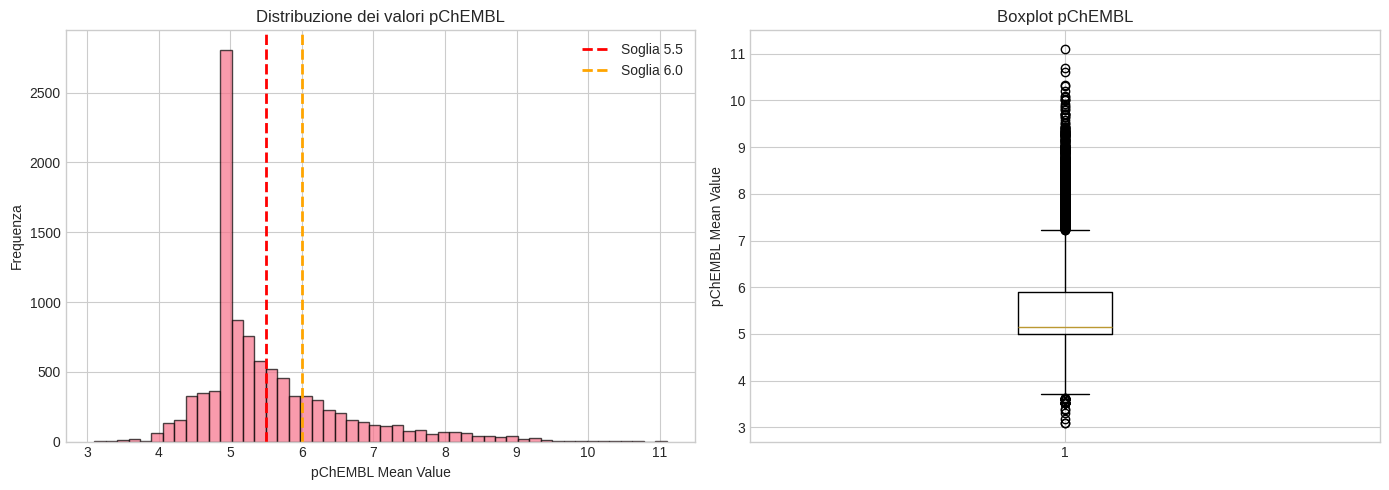


📌 Elementi unici:
   - Molecole uniche (InChIKey): 714
   - Proteine uniche (target_id): 1142
   - Interazioni totali: 10092


In [18]:
# ===============================================================================
# 2.1 ESPLORAZIONE DEL DATASET BIOACTIVITIES
# ===============================================================================

print("=" * 70)
print("DATASET BIOACTIVITIES - Panoramica")
print("=" * 70)

print(f"\nDimensioni: {df_bioactivities.shape[0]} righe × {df_bioactivities.shape[1]} colonne")
print(f"\nColonne principali:")
print(df_bioactivities.columns.tolist()[:15])

# Colonne rilevanti per l'analisi
relevant_cols = ['Activity_ID', 'InChIKey', 'target_id', 'pchembl_value_Mean', 'pchembl_value_Median']
print(f"\n📌 Colonne rilevanti per il nostro task:")
for col in relevant_cols:
    if col in df_bioactivities.columns:
        print(f"   - {col}: {df_bioactivities[col].dtype}")

# Statistiche sul target
print(f"\n📊 Statistiche pchembl_value_Mean:")
print(df_bioactivities['pchembl_value_Mean'].describe())

# Visualizzazione distribuzione pChEMBL
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribuzione pChEMBL
axes[0].hist(df_bioactivities['pchembl_value_Mean'].dropna(), bins=50, edgecolor='black', alpha=0.7)
axes[0].axvline(x=5.5, color='red', linestyle='--', linewidth=2, label='Soglia 5.5')
axes[0].axvline(x=6.0, color='orange', linestyle='--', linewidth=2, label='Soglia 6.0')
axes[0].set_xlabel('pChEMBL Mean Value')
axes[0].set_ylabel('Frequenza')
axes[0].set_title('Distribuzione dei valori pChEMBL')
axes[0].legend()

# Boxplot
axes[1].boxplot(df_bioactivities['pchembl_value_Mean'].dropna())
axes[1].set_ylabel('pChEMBL Mean Value')
axes[1].set_title('Boxplot pChEMBL')

plt.tight_layout()
plt.show()

# Numero di molecole e proteine uniche
print(f"\n📌 Elementi unici:")
print(f"   - Molecole uniche (InChIKey): {df_bioactivities['InChIKey'].nunique()}")
print(f"   - Proteine uniche (target_id): {df_bioactivities['target_id'].nunique()}")
print(f"   - Interazioni totali: {len(df_bioactivities)}")

## 3. Definizione del Target e Preparazione dei Dati

La bioattività viene classificata in base al valore pChEMBL secondo la seguente euristica:
- **Active (1)**: pChEMBL ≥ 6.0
- **Inactive (0)**: pChEMBL < 6.0

In alternativa, si può usare la soglia 5.5 come indicato nel README.

📊 Distribuzione classi di bioattività (soglia: 6.0):
   - Active (1):   2,329 (23.08%)
   - Inactive (0): 7,763 (76.92%)


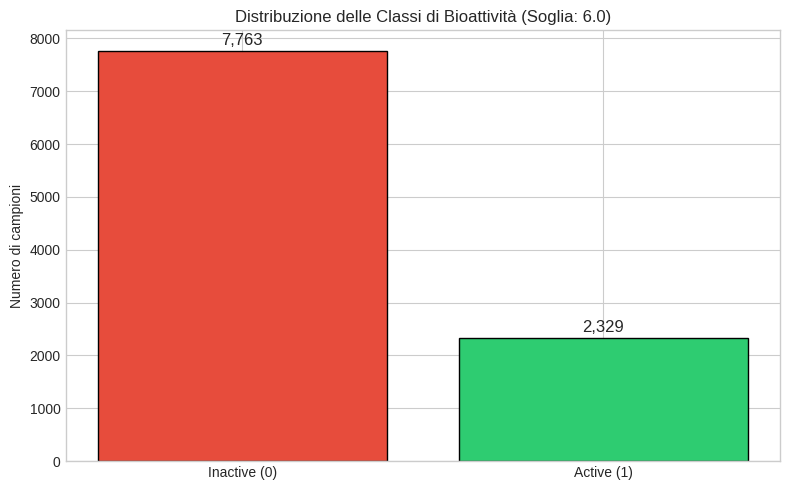

In [19]:
# ===============================================================================
# 3. DEFINIZIONE DEL TARGET - CLASSIFICAZIONE BINARIA
# ===============================================================================

# Soglia per la classificazione (può essere modificata)
PCHEMBL_THRESHOLD = 6.0  # Alternativa: 5.5

def create_bioactivity_label(pchembl_value, threshold=PCHEMBL_THRESHOLD):
    """
    Crea etichetta binaria di bioattività.
    
    Args:
        pchembl_value: valore pChEMBL
        threshold: soglia di classificazione
    
    Returns:
        1 se Active (pChEMBL >= threshold), 0 altrimenti
    """
    if pd.isna(pchembl_value):
        return np.nan
    return 1 if pchembl_value >= threshold else 0

# Applicazione della classificazione
df_bioactivities['bioactivity_class'] = df_bioactivities['pchembl_value_Mean'].apply(
    lambda x: create_bioactivity_label(x, PCHEMBL_THRESHOLD)
)

# Rimozione righe con valori mancanti nel target
df_bio_clean = df_bioactivities.dropna(subset=['bioactivity_class', 'InChIKey', 'target_id'])

print(f"📊 Distribuzione classi di bioattività (soglia: {PCHEMBL_THRESHOLD}):")
class_counts = df_bio_clean['bioactivity_class'].value_counts()
print(f"   - Active (1):   {class_counts.get(1.0, 0):,} ({class_counts.get(1.0, 0)/len(df_bio_clean)*100:.2f}%)")
print(f"   - Inactive (0): {class_counts.get(0.0, 0):,} ({class_counts.get(0.0, 0)/len(df_bio_clean)*100:.2f}%)")

# Visualizzazione bilanciamento classi
fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#e74c3c', '#2ecc71']
bars = ax.bar(['Inactive (0)', 'Active (1)'], 
              [class_counts.get(0.0, 0), class_counts.get(1.0, 0)],
              color=colors, edgecolor='black')
ax.set_ylabel('Numero di campioni')
ax.set_title(f'Distribuzione delle Classi di Bioattività (Soglia: {PCHEMBL_THRESHOLD})')
for bar, count in zip(bars, [class_counts.get(0.0, 0), class_counts.get(1.0, 0)]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50, 
            f'{count:,}', ha='center', va='bottom', fontsize=12)
plt.tight_layout()
plt.show()

## 4. Merge dei Dataset

Assembliamo il dataset finale combinando:
1. **Bioactivities** (target)
2. **Mass Spectra Embeddings** (features molecole) - join su `InChIKey`
3. **Protein Embeddings** (features proteine) - join su `target_id`

Creeremo tre dataset, uno per ciascuna dimensionalità degli embedding proteici.

In [20]:
# ===============================================================================
# 4. MERGE DEI DATASET
# ===============================================================================

def prepare_dataset_with_protein_embedding(df_bio, df_mass, df_protein, protein_name="UniRep"):
    """
    Prepara il dataset finale unendo bioactivities, mass spectra e protein embeddings.
    
    Args:
        df_bio: DataFrame con le bioattività
        df_mass: DataFrame con gli embedding degli spettri di massa
        df_protein: DataFrame con gli embedding delle proteine
        protein_name: Nome del tipo di embedding proteico
    
    Returns:
        DataFrame unificato pronto per il training
    """
    print(f"\n{'='*60}")
    print(f"Preparazione dataset con {protein_name}")
    print(f"{'='*60}")
    
    # Step 1: Selezione colonne rilevanti da bioactivities
    bio_cols = ['Activity_ID', 'InChIKey', 'target_id', 'bioactivity_class']
    df_bio_subset = df_bio[bio_cols].copy()
    
    # Step 2: Preparazione mass spectra embeddings
    # La colonna 'inchikey' nel dataset mass spectra include la parte completa
    # Dobbiamo matchare solo la prima parte (14 caratteri) che è il backbone
    df_mass_copy = df_mass.copy()
    df_mass_copy['InChIKey_short'] = df_mass_copy['inchikey'].str[:27]  # Full InChIKey
    
    # Colonne di features (0-499) + identificatore
    mass_feature_cols = [str(i) for i in range(500)]
    mass_cols_to_keep = ['InChIKey_short'] + mass_feature_cols
    df_mass_subset = df_mass_copy[mass_cols_to_keep].copy()
    
    # Rimuovi duplicati mantenendo il primo
    df_mass_subset = df_mass_subset.drop_duplicates(subset=['InChIKey_short'], keep='first')
    
    # Step 3: Merge con mass spectra
    print(f"   Campioni iniziali: {len(df_bio_subset)}")
    df_merged = pd.merge(
        df_bio_subset, 
        df_mass_subset, 
        left_on='InChIKey', 
        right_on='InChIKey_short',
        how='inner'
    )
    print(f"   Dopo merge con mass spectra: {len(df_merged)}")
    
    # Step 4: Merge con protein embeddings
    protein_feature_cols = [col for col in df_protein.columns if col != 'target_id']
    df_merged = pd.merge(
        df_merged,
        df_protein,
        on='target_id',
        how='inner'
    )
    print(f"   Dopo merge con protein embeddings: {len(df_merged)}")
    
    # Step 5: Rimozione duplicati e colonne temporanee
    df_merged = df_merged.drop_duplicates(subset=['Activity_ID'], keep='first')
    if 'InChIKey_short' in df_merged.columns:
        df_merged = df_merged.drop(columns=['InChIKey_short'])
    
    print(f"   Dataset finale: {len(df_merged)}")
    print(f"   Features totali: {len(mass_feature_cols) + len(protein_feature_cols)}")
    
    return df_merged, mass_feature_cols, protein_feature_cols

# Preparazione dei tre dataset
print("🔄 Assemblaggio dei dataset...")

df_dataset_64, mass_cols, protein_cols_64 = prepare_dataset_with_protein_embedding(
    df_bio_clean, df_mass_spectra, df_protein_64, "UniRep64 (192 features)"
)

df_dataset_256, _, protein_cols_256 = prepare_dataset_with_protein_embedding(
    df_bio_clean, df_mass_spectra, df_protein_256, "UniRep256 (768 features)"
)

df_dataset_1900, _, protein_cols_1900 = prepare_dataset_with_protein_embedding(
    df_bio_clean, df_mass_spectra, df_protein_1900, "UniRep1900 (5700 features)"
)

print("\n✅ Tutti i dataset sono stati preparati!")

🔄 Assemblaggio dei dataset...

Preparazione dataset con UniRep64 (192 features)
   Campioni iniziali: 10092
   Dopo merge con mass spectra: 10092
   Dopo merge con protein embeddings: 10092
   Dataset finale: 10092
   Features totali: 692

Preparazione dataset con UniRep256 (768 features)
   Campioni iniziali: 10092
   Dopo merge con mass spectra: 10092
   Dopo merge con protein embeddings: 10092
   Dataset finale: 10092
   Features totali: 1268

Preparazione dataset con UniRep1900 (5700 features)
   Campioni iniziali: 10092
   Dopo merge con mass spectra: 10092
   Dopo merge con protein embeddings: 10092
   Dataset finale: 10092
   Features totali: 6200

✅ Tutti i dataset sono stati preparati!


In [21]:
# ===============================================================================
# 4.1 VERIFICA DEI DATASET PREPARATI
# ===============================================================================

# Statistiche sui dataset
datasets_info = {
    'UniRep64': {
        'df': df_dataset_64,
        'n_features': len(mass_cols) + len(protein_cols_64),
        'protein_features': len(protein_cols_64)
    },
    'UniRep256': {
        'df': df_dataset_256,
        'n_features': len(mass_cols) + len(protein_cols_256),
        'protein_features': len(protein_cols_256)
    },
    'UniRep1900': {
        'df': df_dataset_1900,
        'n_features': len(mass_cols) + len(protein_cols_1900),
        'protein_features': len(protein_cols_1900)
    }
}

print("📊 Riepilogo dei Dataset:\n")
print(f"{'Dataset':<15} {'Campioni':>10} {'Features':>10} {'Protein F.':>12} {'Mass F.':>10}")
print("-" * 60)

for name, info in datasets_info.items():
    print(f"{name:<15} {len(info['df']):>10,} {info['n_features']:>10} {info['protein_features']:>12} {len(mass_cols):>10}")

# Verifica distribuzione classi nei dataset
print(f"\n📊 Distribuzione classi nei dataset:")
for name, info in datasets_info.items():
    class_dist = info['df']['bioactivity_class'].value_counts()
    active_pct = class_dist.get(1.0, 0) / len(info['df']) * 100
    print(f"   {name}: Active {class_dist.get(1.0, 0):,} ({active_pct:.1f}%), Inactive {class_dist.get(0.0, 0):,} ({100-active_pct:.1f}%)")

📊 Riepilogo dei Dataset:

Dataset           Campioni   Features   Protein F.    Mass F.
------------------------------------------------------------
UniRep64            10,092        692          192        500
UniRep256           10,092       1268          768        500
UniRep1900          10,092       6200         5700        500

📊 Distribuzione classi nei dataset:
   UniRep64: Active 2,329 (23.1%), Inactive 7,763 (76.9%)
   UniRep256: Active 2,329 (23.1%), Inactive 7,763 (76.9%)
   UniRep1900: Active 2,329 (23.1%), Inactive 7,763 (76.9%)


## 5. Preprocessing e Feature Engineering

Prepariamo i dati per il training:
1. Separazione features e target
2. Split train/test stratificato
3. Normalizzazione delle features
4. Gestione dello sbilanciamento delle classi

In [22]:
# ===============================================================================
# 5. PREPROCESSING E PREPARAZIONE DEI DATI
# ===============================================================================

def prepare_train_test_data(df, feature_cols, target_col='bioactivity_class', test_size=0.2):
    """
    Prepara i dati per il training con split stratificato e normalizzazione.
    
    Args:
        df: DataFrame con i dati
        feature_cols: Lista delle colonne features
        target_col: Nome della colonna target
        test_size: Proporzione del test set
    
    Returns:
        X_train, X_test, y_train, y_test, scaler
    """
    # Estrazione features e target
    X = df[feature_cols].values
    y = df[target_col].values.astype(int)
    
    # Gestione valori mancanti nelle features
    imputer = SimpleImputer(strategy='median')
    X = imputer.fit_transform(X)
    
    # Split stratificato
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=RANDOM_STATE, stratify=y
    )
    
    # Normalizzazione
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    
    return X_train, X_test, y_train, y_test, scaler

# Preparazione dei dati per ciascun dataset
print("🔄 Preparazione dei dati per il training...\n")

# Dataset con UniRep64
feature_cols_64 = mass_cols + protein_cols_64
X_train_64, X_test_64, y_train_64, y_test_64, scaler_64 = prepare_train_test_data(
    df_dataset_64, feature_cols_64
)
print(f"UniRep64: Train {X_train_64.shape}, Test {X_test_64.shape}")

# Dataset con UniRep256
feature_cols_256 = mass_cols + protein_cols_256
X_train_256, X_test_256, y_train_256, y_test_256, scaler_256 = prepare_train_test_data(
    df_dataset_256, feature_cols_256
)
print(f"UniRep256: Train {X_train_256.shape}, Test {X_test_256.shape}")

# Dataset con UniRep1900
feature_cols_1900 = mass_cols + protein_cols_1900
X_train_1900, X_test_1900, y_train_1900, y_test_1900, scaler_1900 = prepare_train_test_data(
    df_dataset_1900, feature_cols_1900
)
print(f"UniRep1900: Train {X_train_1900.shape}, Test {X_test_1900.shape}")

# Calcolo pesi delle classi per gestire lo sbilanciamento
class_weights_64 = {0: len(y_train_64) / (2 * np.sum(y_train_64 == 0)),
                    1: len(y_train_64) / (2 * np.sum(y_train_64 == 1))}
print(f"\n📊 Pesi delle classi (per gestire sbilanciamento):")
print(f"   Classe 0 (Inactive): {class_weights_64[0]:.3f}")
print(f"   Classe 1 (Active): {class_weights_64[1]:.3f}")

print("\n✅ Dati preparati per il training!")

🔄 Preparazione dei dati per il training...

UniRep64: Train (8073, 692), Test (2019, 692)
UniRep256: Train (8073, 1268), Test (2019, 1268)
UniRep1900: Train (8073, 6200), Test (2019, 6200)

📊 Pesi delle classi (per gestire sbilanciamento):
   Classe 0 (Inactive): 0.650
   Classe 1 (Active): 2.167

✅ Dati preparati per il training!


## 6. Definizione dei Modelli

Implementeremo diversi modelli di machine learning:
1. **Random Forest** - Ensemble di alberi decisionali
2. **XGBoost** - Gradient boosting ottimizzato
3. **Neural Network (MLP)** - Rete neurale con PyTorch (ottimizzata per GPU)

In [ ]:
# ===============================================================================
# 6. DEFINIZIONE DEI MODELLI
# ===============================================================================

def get_models(class_weight_dict=None, input_dim=None):
    """
    Restituisce un dizionario con i modelli da addestrare.
    
    Args:
        class_weight_dict: Dizionario con i pesi delle classi
        input_dim: Dimensione dell'input per la rete neurale
    
    Returns:
        Dizionario con i modelli
    """
    models = {
        'Random Forest': RandomForestClassifier(
            n_estimators=200,
            max_depth=20,
            min_samples_split=5,
            min_samples_leaf=2,
            class_weight='balanced',
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        'XGBoost': xgb.XGBClassifier(
            n_estimators=200,
            max_depth=10,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=class_weight_dict[1] / class_weight_dict[0] if class_weight_dict else 1,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            use_label_encoder=False,
            eval_metric='logloss',
            tree_method='hist',  # Usa GPU se disponibile con 'gpu_hist'
            device='cuda' if torch.cuda.is_available() else 'cpu'
        ),
        'Gradient Boosting': GradientBoostingClassifier(
            n_estimators=150,
            max_depth=8,
            learning_rate=0.1,
            subsample=0.8,
            random_state=RANDOM_STATE
        )
    }
    return models

print("✅ Modelli definiti: Random Forest, XGBoost, Gradient Boosting")
print("📌 Nota: I modelli utilizzano pesi bilanciati per gestire lo sbilanciamento delle classi")

In [ ]:
# ===============================================================================
# 6.1 RETE NEURALE PROFONDA CON PYTORCH (GPU-ACCELERATED)
# ===============================================================================

class BioactivityMLP(nn.Module):
    """
    Rete neurale Multi-Layer Perceptron per la predizione della bioattività.
    Ottimizzata per l'esecuzione su GPU.
    """
    def __init__(self, input_dim, hidden_dims=[512, 256, 128], dropout_rate=0.3):
        super(BioactivityMLP, self).__init__()
        
        layers = []
        prev_dim = input_dim
        
        for hidden_dim in hidden_dims:
            layers.extend([
                nn.Linear(prev_dim, hidden_dim),
                nn.BatchNorm1d(hidden_dim),
                nn.ReLU(),
                nn.Dropout(dropout_rate)
            ])
            prev_dim = hidden_dim
        
        # Output layer
        layers.append(nn.Linear(prev_dim, 1))
        layers.append(nn.Sigmoid())
        
        self.network = nn.Sequential(*layers)
        
    def forward(self, x):
        return self.network(x)


def train_neural_network(X_train, y_train, X_test, y_test, input_dim, 
                         hidden_dims=[512, 256, 128], epochs=100, batch_size=64,
                         learning_rate=0.001, device=DEVICE, class_weights=None):
    """
    Addestra la rete neurale con early stopping.
    
    Args:
        X_train, y_train: Dati di training
        X_test, y_test: Dati di test
        input_dim: Dimensione dell'input
        hidden_dims: Dimensioni dei layer nascosti
        epochs: Numero massimo di epoche
        batch_size: Dimensione del batch
        learning_rate: Learning rate
        device: Device (cuda/cpu)
        class_weights: Pesi delle classi
    
    Returns:
        Modello addestrato, storia del training
    """
    # Preparazione dei dati per PyTorch
    X_train_tensor = torch.FloatTensor(X_train).to(device)
    y_train_tensor = torch.FloatTensor(y_train).unsqueeze(1).to(device)
    X_test_tensor = torch.FloatTensor(X_test).to(device)
    y_test_tensor = torch.FloatTensor(y_test).unsqueeze(1).to(device)
    
    train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    
    # Inizializzazione modello
    model = BioactivityMLP(input_dim, hidden_dims).to(device)
    
    # Loss function con pesi per le classi sbilanciate
    if class_weights is not None:
        pos_weight = torch.tensor([class_weights[1] / class_weights[0]]).to(device)
        criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    else:
        criterion = nn.BCELoss()
    
    optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-5)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)
    
    # Training loop con early stopping
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    best_val_loss = float('inf')
    patience_counter = 0
    patience = 15
    
    for epoch in range(epochs):
        model.train()
        train_loss = 0
        
        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
        
        train_loss /= len(train_loader)
        
        # Validazione
        model.eval()
        with torch.no_grad():
            val_outputs = model(X_test_tensor)
            val_loss = criterion(val_outputs, y_test_tensor).item()
            val_preds = (val_outputs.cpu().numpy() > 0.5).astype(int)
            val_acc = accuracy_score(y_test, val_preds)
        
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        
        scheduler.step(val_loss)
        
        # Early stopping
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
            best_model_state = model.state_dict().copy()
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"   Early stopping at epoch {epoch+1}")
                break
        
        if (epoch + 1) % 20 == 0:
            print(f"   Epoch {epoch+1}/{epochs} - Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")
    
    # Carica il miglior modello
    model.load_state_dict(best_model_state)
    
    return model, history

print("✅ Architettura della rete neurale definita")
print(f"📌 Device: {DEVICE}")

## 7. Training e Valutazione dei Modelli

Addestriamo i modelli su ciascuno dei tre dataset (UniRep64, UniRep256, UniRep1900) e confrontiamo le performance.

In [ ]:
# ===============================================================================
# 7. FUNZIONI DI TRAINING E VALUTAZIONE
# ===============================================================================

def evaluate_model(model, X_test, y_test, model_name="Model"):
    """
    Valuta un modello e restituisce le metriche.
    
    Args:
        model: Modello addestrato
        X_test, y_test: Dati di test
        model_name: Nome del modello
    
    Returns:
        Dizionario con le metriche
    """
    # Predizioni
    if isinstance(model, nn.Module):
        model.eval()
        with torch.no_grad():
            X_test_tensor = torch.FloatTensor(X_test).to(DEVICE)
            y_prob = model(X_test_tensor).cpu().numpy().flatten()
            y_pred = (y_prob > 0.5).astype(int)
    else:
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else None
    
    # Metriche
    metrics = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob) if y_prob is not None else None
    }
    
    return metrics, y_pred, y_prob


def train_and_evaluate_all_models(X_train, X_test, y_train, y_test, 
                                   embedding_name, class_weights):
    """
    Addestra e valuta tutti i modelli per un dataset.
    
    Args:
        X_train, X_test, y_train, y_test: Dati
        embedding_name: Nome dell'embedding proteico
        class_weights: Pesi delle classi
    
    Returns:
        Dizionario con i risultati
    """
    print(f"\n{'='*70}")
    print(f"TRAINING MODELLI - {embedding_name}")
    print(f"{'='*70}")
    
    results = {}
    trained_models = {}
    
    # Ottieni i modelli
    models = get_models(class_weights, input_dim=X_train.shape[1])
    
    # Training modelli tradizionali
    for name, model in models.items():
        print(f"\n🔄 Training {name}...")
        start_time = time.time()
        
        model.fit(X_train, y_train)
        
        training_time = time.time() - start_time
        metrics, y_pred, y_prob = evaluate_model(model, X_test, y_test, name)
        metrics['Training Time'] = training_time
        
        results[name] = metrics
        trained_models[name] = model
        
        print(f"   ✅ Completato in {training_time:.2f}s")
        print(f"   Accuracy: {metrics['Accuracy']:.4f}, F1: {metrics['F1-Score']:.4f}, ROC-AUC: {metrics['ROC-AUC']:.4f}")
    
    # Training Neural Network
    print(f"\n🔄 Training Neural Network (MLP)...")
    start_time = time.time()
    
    nn_model, nn_history = train_neural_network(
        X_train, y_train, X_test, y_test,
        input_dim=X_train.shape[1],
        hidden_dims=[512, 256, 128],
        epochs=100,
        batch_size=64,
        class_weights=class_weights
    )
    
    training_time = time.time() - start_time
    nn_metrics, nn_pred, nn_prob = evaluate_model(nn_model, X_test, y_test, "Neural Network")
    nn_metrics['Training Time'] = training_time
    
    results['Neural Network'] = nn_metrics
    trained_models['Neural Network'] = nn_model
    
    print(f"   ✅ Completato in {training_time:.2f}s")
    print(f"   Accuracy: {nn_metrics['Accuracy']:.4f}, F1: {nn_metrics['F1-Score']:.4f}, ROC-AUC: {nn_metrics['ROC-AUC']:.4f}")
    
    return results, trained_models, nn_history

print("✅ Funzioni di training e valutazione definite")

In [ ]:
# ===============================================================================
# 7.1 TRAINING SU TUTTI I DATASET
# ===============================================================================

# Dizionario per salvare tutti i risultati
all_results = {}
all_models = {}
nn_histories = {}

# Training su UniRep64
results_64, models_64, history_64 = train_and_evaluate_all_models(
    X_train_64, X_test_64, y_train_64, y_test_64,
    "UniRep64 (192 features)", class_weights_64
)
all_results['UniRep64'] = results_64
all_models['UniRep64'] = models_64
nn_histories['UniRep64'] = history_64

# Training su UniRep256
class_weights_256 = {0: len(y_train_256) / (2 * np.sum(y_train_256 == 0)),
                     1: len(y_train_256) / (2 * np.sum(y_train_256 == 1))}
results_256, models_256, history_256 = train_and_evaluate_all_models(
    X_train_256, X_test_256, y_train_256, y_test_256,
    "UniRep256 (768 features)", class_weights_256
)
all_results['UniRep256'] = results_256
all_models['UniRep256'] = models_256
nn_histories['UniRep256'] = history_256

# Training su UniRep1900
class_weights_1900 = {0: len(y_train_1900) / (2 * np.sum(y_train_1900 == 0)),
                      1: len(y_train_1900) / (2 * np.sum(y_train_1900 == 1))}
results_1900, models_1900, history_1900 = train_and_evaluate_all_models(
    X_train_1900, X_test_1900, y_train_1900, y_test_1900,
    "UniRep1900 (5700 features)", class_weights_1900
)
all_results['UniRep1900'] = results_1900
all_models['UniRep1900'] = models_1900
nn_histories['UniRep1900'] = history_1900

print("\n" + "="*70)
print("✅ TRAINING COMPLETATO PER TUTTI I MODELLI E DATASET!")
print("="*70)

## 8. Confronto dei Risultati

Confrontiamo le performance dei modelli sui tre dataset con diverse dimensionalità degli embedding proteici.

In [ ]:
# ===============================================================================
# 8. CONFRONTO DEI RISULTATI
# ===============================================================================

def create_results_dataframe(all_results):
    """
    Crea un DataFrame con tutti i risultati per il confronto.
    """
    rows = []
    for embedding, models_results in all_results.items():
        for model_name, metrics in models_results.items():
            row = {
                'Embedding': embedding,
                'Model': model_name,
                **metrics
            }
            rows.append(row)
    return pd.DataFrame(rows)

# Creazione DataFrame risultati
df_results = create_results_dataframe(all_results)

# Visualizzazione tabella riassuntiva
print("="*90)
print("TABELLA RIASSUNTIVA DEI RISULTATI")
print("="*90)

# Formattazione per la stampa
results_display = df_results.copy()
for col in ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']:
    results_display[col] = results_display[col].apply(lambda x: f"{x:.4f}" if x is not None else "N/A")
results_display['Training Time'] = results_display['Training Time'].apply(lambda x: f"{x:.2f}s")

print(results_display.to_string(index=False))

# Pivot table per confronto migliore
print("\n" + "="*90)
print("CONFRONTO ROC-AUC PER MODELLO ED EMBEDDING")
print("="*90)
pivot_auc = df_results.pivot(index='Model', columns='Embedding', values='ROC-AUC')
print(pivot_auc.round(4).to_string())

print("\n" + "="*90)
print("CONFRONTO F1-SCORE PER MODELLO ED EMBEDDING")
print("="*90)
pivot_f1 = df_results.pivot(index='Model', columns='Embedding', values='F1-Score')
print(pivot_f1.round(4).to_string())

In [ ]:
# ===============================================================================
# 8.1 VISUALIZZAZIONE GRAFICA DEI RISULTATI
# ===============================================================================

# Figura 1: Confronto metriche per embedding
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
colors = {'UniRep64': '#3498db', 'UniRep256': '#e74c3c', 'UniRep1900': '#2ecc71'}

for idx, metric in enumerate(metrics_to_plot):
    ax = axes[idx // 2, idx % 2]
    
    pivot_data = df_results.pivot(index='Model', columns='Embedding', values=metric)
    x = np.arange(len(pivot_data.index))
    width = 0.25
    
    for i, embedding in enumerate(['UniRep64', 'UniRep256', 'UniRep1900']):
        bars = ax.bar(x + i*width, pivot_data[embedding], width, 
                      label=embedding, color=colors[embedding], alpha=0.8)
    
    ax.set_ylabel(metric)
    ax.set_title(f'{metric} per Modello ed Embedding')
    ax.set_xticks(x + width)
    ax.set_xticklabels(pivot_data.index, rotation=45, ha='right')
    ax.legend()
    ax.set_ylim([0, 1])
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('comparison_metrics.png', dpi=150, bbox_inches='tight')
plt.show()

# Figura 2: ROC-AUC comparison
fig, ax = plt.subplots(figsize=(12, 6))
pivot_auc = df_results.pivot(index='Model', columns='Embedding', values='ROC-AUC')
pivot_auc.plot(kind='bar', ax=ax, color=[colors['UniRep64'], colors['UniRep256'], colors['UniRep1900']], 
               alpha=0.8, edgecolor='black')
ax.set_ylabel('ROC-AUC Score')
ax.set_title('Confronto ROC-AUC per Modello ed Embedding Proteico')
ax.set_xticklabels(pivot_auc.index, rotation=45, ha='right')
ax.legend(title='Protein Embedding')
ax.set_ylim([0.5, 1])
ax.grid(axis='y', alpha=0.3)
ax.axhline(y=0.5, color='red', linestyle='--', alpha=0.5, label='Random')
plt.tight_layout()
plt.savefig('roc_auc_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ Grafici salvati: comparison_metrics.png, roc_auc_comparison.png")

In [ ]:
# ===============================================================================
# 8.2 CURVE ROC E CONFUSION MATRIX PER IL MIGLIOR MODELLO
# ===============================================================================

def plot_roc_curves_and_confusion_matrix(models_dict, X_test, y_test, embedding_name):
    """
    Plotta le curve ROC e la confusion matrix per i modelli.
    """
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # ROC Curves
    ax1 = axes[0]
    for name, model in models_dict.items():
        if isinstance(model, nn.Module):
            model.eval()
            with torch.no_grad():
                X_test_tensor = torch.FloatTensor(X_test).to(DEVICE)
                y_prob = model(X_test_tensor).cpu().numpy().flatten()
        else:
            if hasattr(model, 'predict_proba'):
                y_prob = model.predict_proba(X_test)[:, 1]
            else:
                continue
        
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        auc_score = roc_auc_score(y_test, y_prob)
        ax1.plot(fpr, tpr, label=f'{name} (AUC = {auc_score:.3f})', linewidth=2)
    
    ax1.plot([0, 1], [0, 1], 'k--', label='Random (AUC = 0.5)')
    ax1.set_xlabel('False Positive Rate')
    ax1.set_ylabel('True Positive Rate')
    ax1.set_title(f'ROC Curves - {embedding_name}')
    ax1.legend(loc='lower right')
    ax1.grid(alpha=0.3)
    
    # Confusion Matrix per il miglior modello (XGBoost)
    ax2 = axes[1]
    best_model = models_dict.get('XGBoost', list(models_dict.values())[0])
    if isinstance(best_model, nn.Module):
        best_model.eval()
        with torch.no_grad():
            X_test_tensor = torch.FloatTensor(X_test).to(DEVICE)
            y_pred = (best_model(X_test_tensor).cpu().numpy() > 0.5).astype(int).flatten()
    else:
        y_pred = best_model.predict(X_test)
    
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax2,
                xticklabels=['Inactive', 'Active'],
                yticklabels=['Inactive', 'Active'])
    ax2.set_xlabel('Predicted')
    ax2.set_ylabel('Actual')
    ax2.set_title(f'Confusion Matrix (XGBoost) - {embedding_name}')
    
    plt.tight_layout()
    plt.savefig(f'roc_cm_{embedding_name.replace(" ", "_").lower()}.png', dpi=150, bbox_inches='tight')
    plt.show()

# Genera i plot per ciascun embedding
for embedding_name, (X_test, y_test) in [
    ('UniRep64', (X_test_64, y_test_64)),
    ('UniRep256', (X_test_256, y_test_256)),
    ('UniRep1900', (X_test_1900, y_test_1900))
]:
    print(f"\n📊 Visualizzazioni per {embedding_name}:")
    plot_roc_curves_and_confusion_matrix(
        all_models[embedding_name], X_test, y_test, embedding_name
    )

In [ ]:
# ===============================================================================
# 8.3 LEARNING CURVES DELLE RETI NEURALI
# ===============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (embedding_name, history) in enumerate(nn_histories.items()):
    ax = axes[idx]
    epochs_range = range(1, len(history['train_loss']) + 1)
    
    # Plot Loss
    ax.plot(epochs_range, history['train_loss'], 'b-', label='Training Loss', linewidth=2)
    ax.plot(epochs_range, history['val_loss'], 'r-', label='Validation Loss', linewidth=2)
    
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.set_title(f'Learning Curve - Neural Network ({embedding_name})')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('learning_curves_nn.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ Learning curves salvate: learning_curves_nn.png")

## 9. Feature Importance Analysis

Analizziamo quali features sono più importanti per la predizione della bioattività utilizzando il modello Random Forest.

In [ ]:
# ===============================================================================
# 9. FEATURE IMPORTANCE ANALYSIS
# ===============================================================================

def analyze_feature_importance(model, feature_names, top_n=20, title="Feature Importance"):
    """
    Analizza e visualizza l'importanza delle features.
    """
    if hasattr(model, 'feature_importances_'):
        importances = model.feature_importances_
    else:
        print("Il modello non supporta feature_importances_")
        return None
    
    # Crea DataFrame con importanze
    importance_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importances
    }).sort_values('Importance', ascending=False)
    
    # Classifica le features per tipo
    importance_df['Type'] = importance_df['Feature'].apply(
        lambda x: 'Mass Spectra' if x.isdigit() else 'Protein'
    )
    
    # Top N features
    top_features = importance_df.head(top_n)
    
    # Visualizzazione
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Barplot top features
    ax1 = axes[0]
    colors = ['#3498db' if t == 'Mass Spectra' else '#e74c3c' for t in top_features['Type']]
    ax1.barh(range(top_n), top_features['Importance'].values, color=colors)
    ax1.set_yticks(range(top_n))
    ax1.set_yticklabels(top_features['Feature'].values)
    ax1.invert_yaxis()
    ax1.set_xlabel('Importance')
    ax1.set_title(f'{title} - Top {top_n} Features')
    
    # Legenda
    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor='#3498db', label='Mass Spectra'),
                       Patch(facecolor='#e74c3c', label='Protein Embedding')]
    ax1.legend(handles=legend_elements, loc='lower right')
    
    # Pie chart distribuzione importanza per tipo
    ax2 = axes[1]
    type_importance = importance_df.groupby('Type')['Importance'].sum()
    ax2.pie(type_importance.values, labels=type_importance.index, autopct='%1.1f%%',
            colors=['#3498db', '#e74c3c'], explode=[0.02, 0.02])
    ax2.set_title('Distribuzione Importanza per Tipo di Feature')
    
    plt.tight_layout()
    return importance_df

# Analisi feature importance per UniRep64 (più interpretabile)
print("📊 Analisi Feature Importance - UniRep64 (Random Forest)")
rf_model_64 = all_models['UniRep64']['Random Forest']
importance_df_64 = analyze_feature_importance(
    rf_model_64, feature_cols_64, top_n=25,
    title="Random Forest - UniRep64"
)
plt.savefig('feature_importance_64.png', dpi=150, bbox_inches='tight')
plt.show()

# Statistiche aggregate
if importance_df_64 is not None:
    print("\n📊 Statistiche Feature Importance:")
    print(importance_df_64.groupby('Type')['Importance'].agg(['sum', 'mean', 'std']).round(4))

## 10. Cross-Validation per Robustezza

Eseguiamo una cross-validation stratificata per valutare la robustezza dei modelli e ottenere intervalli di confidenza sulle performance.

In [ ]:
# ===============================================================================
# 10. CROSS-VALIDATION STRATIFICATA
# ===============================================================================

def cross_validate_models(X, y, models_dict, n_folds=5):
    """
    Esegue cross-validation stratificata per tutti i modelli.
    
    Args:
        X, y: Features e target
        models_dict: Dizionario dei modelli
        n_folds: Numero di fold
    
    Returns:
        DataFrame con i risultati della cross-validation
    """
    cv = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=RANDOM_STATE)
    
    cv_results = []
    
    for name, model in models_dict.items():
        if isinstance(model, nn.Module):
            continue  # Skip neural network per CV (troppo lento)
        
        # Clone del modello per non modificare l'originale
        from sklearn.base import clone
        model_clone = clone(model)
        
        # Cross-validation scores
        scores = cross_val_score(model_clone, X, y, cv=cv, scoring='roc_auc', n_jobs=-1)
        
        cv_results.append({
            'Model': name,
            'Mean ROC-AUC': scores.mean(),
            'Std ROC-AUC': scores.std(),
            'Min ROC-AUC': scores.min(),
            'Max ROC-AUC': scores.max()
        })
    
    return pd.DataFrame(cv_results)

# Cross-validation per UniRep64 (dataset più piccolo, più veloce)
print("🔄 Cross-Validation (5-fold) - UniRep64...")
print("   Questo potrebbe richiedere qualche minuto...\n")

# Prepara i dati completi
X_full_64 = np.vstack([X_train_64, X_test_64])
y_full_64 = np.concatenate([y_train_64, y_test_64])

cv_results_64 = cross_validate_models(
    X_full_64, y_full_64,
    {k: v for k, v in all_models['UniRep64'].items() if not isinstance(v, nn.Module)}
)

print("📊 Risultati Cross-Validation - UniRep64:")
print(cv_results_64.to_string(index=False))

# Visualizzazione
fig, ax = plt.subplots(figsize=(10, 6))
x = range(len(cv_results_64))
ax.bar(x, cv_results_64['Mean ROC-AUC'], yerr=cv_results_64['Std ROC-AUC'],
       capsize=5, color=['#3498db', '#e74c3c', '#2ecc71'][:len(cv_results_64)], alpha=0.8)
ax.set_xticks(x)
ax.set_xticklabels(cv_results_64['Model'], rotation=45, ha='right')
ax.set_ylabel('ROC-AUC')
ax.set_title('Cross-Validation Results (5-fold) - UniRep64')
ax.set_ylim([0.5, 1])
ax.grid(axis='y', alpha=0.3)

for i, row in cv_results_64.iterrows():
    ax.text(i, row['Mean ROC-AUC'] + row['Std ROC-AUC'] + 0.02, 
            f"{row['Mean ROC-AUC']:.3f}±{row['Std ROC-AUC']:.3f}",
            ha='center', fontsize=10)

plt.tight_layout()
plt.savefig('cross_validation_results.png', dpi=150, bbox_inches='tight')
plt.show()

## 11. Salvataggio dei Modelli e Risultati

Salviamo i modelli addestrati e i risultati per un utilizzo futuro.

In [ ]:
# ===============================================================================
# 11. SALVATAGGIO DEI MODELLI E RISULTATI
# ===============================================================================

import pickle
import json
from datetime import datetime

# Crea directory per i risultati
output_dir = Path('results')
output_dir.mkdir(exist_ok=True)

# 1. Salva i risultati in CSV
df_results.to_csv(output_dir / 'model_results.csv', index=False)
print("✅ Risultati salvati in: results/model_results.csv")

# 2. Salva i modelli sklearn
for embedding_name, models in all_models.items():
    for model_name, model in models.items():
        if not isinstance(model, nn.Module):
            filename = f"{embedding_name}_{model_name.replace(' ', '_')}.pkl"
            with open(output_dir / filename, 'wb') as f:
                pickle.dump(model, f)
            print(f"✅ Modello salvato: results/{filename}")

# 3. Salva i modelli PyTorch
for embedding_name, models in all_models.items():
    nn_model = models.get('Neural Network')
    if nn_model is not None and isinstance(nn_model, nn.Module):
        filename = f"{embedding_name}_Neural_Network.pt"
        torch.save(nn_model.state_dict(), output_dir / filename)
        print(f"✅ Modello NN salvato: results/{filename}")

# 4. Salva gli scaler
scalers = {'UniRep64': scaler_64, 'UniRep256': scaler_256, 'UniRep1900': scaler_1900}
for name, scaler in scalers.items():
    with open(output_dir / f'scaler_{name}.pkl', 'wb') as f:
        pickle.dump(scaler, f)
print("✅ Scaler salvati")

# 5. Salva configurazione e metadata
metadata = {
    'timestamp': datetime.now().isoformat(),
    'random_state': RANDOM_STATE,
    'pchembl_threshold': PCHEMBL_THRESHOLD,
    'device': str(DEVICE),
    'pytorch_version': torch.__version__,
    'datasets': {
        'UniRep64': {'n_samples': len(df_dataset_64), 'n_features': len(feature_cols_64)},
        'UniRep256': {'n_samples': len(df_dataset_256), 'n_features': len(feature_cols_256)},
        'UniRep1900': {'n_samples': len(df_dataset_1900), 'n_features': len(feature_cols_1900)}
    }
}

with open(output_dir / 'metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)
print("✅ Metadata salvati in: results/metadata.json")

print(f"\n📁 Tutti i risultati sono stati salvati nella directory: {output_dir.absolute()}")

## 12. Conclusioni e Discussione

### Riepilogo dei Risultati

In questo progetto abbiamo sviluppato modelli di machine learning per predire la bioattività di molecole derivate da piante, utilizzando tre diverse dimensionalità di embedding proteici (UniRep64, UniRep256, UniRep1900).

In [ ]:
# ===============================================================================
# 12. RIEPILOGO FINALE E CONCLUSIONI
# ===============================================================================

print("="*80)
print("RIEPILOGO FINALE DEL PROGETTO")
print("="*80)

print("\n📋 OBIETTIVO:")
print("   Predire la bioattività (Active/Inactive) di molecole basandosi su:")
print("   - Embedding degli spettri di massa (Spec2Vec, 500 features)")
print("   - Embedding delle proteine target (UniRep, 3 dimensionalità)")

print("\n📊 DATASET:")
print(f"   - Soglia pChEMBL utilizzata: {PCHEMBL_THRESHOLD}")
for name, info in datasets_info.items():
    print(f"   - {name}: {len(info['df']):,} campioni, {info['n_features']} features")

print("\n🏆 MIGLIORI RISULTATI PER EMBEDDING:")
for embedding in ['UniRep64', 'UniRep256', 'UniRep1900']:
    best_model = df_results[df_results['Embedding'] == embedding].sort_values('ROC-AUC', ascending=False).iloc[0]
    print(f"   {embedding}: {best_model['Model']} (ROC-AUC: {best_model['ROC-AUC']:.4f}, F1: {best_model['F1-Score']:.4f})")

print("\n📈 CONFRONTO DIMENSIONALITÀ EMBEDDING:")
avg_by_embedding = df_results.groupby('Embedding')[['ROC-AUC', 'F1-Score', 'Accuracy']].mean()
print(avg_by_embedding.round(4).to_string())

# Trova il miglior risultato assoluto
best_overall = df_results.sort_values('ROC-AUC', ascending=False).iloc[0]
print(f"\n🥇 MIGLIOR MODELLO ASSOLUTO:")
print(f"   {best_overall['Model']} con {best_overall['Embedding']}")
print(f"   - ROC-AUC:   {best_overall['ROC-AUC']:.4f}")
print(f"   - F1-Score:  {best_overall['F1-Score']:.4f}")
print(f"   - Accuracy:  {best_overall['Accuracy']:.4f}")
print(f"   - Precision: {best_overall['Precision']:.4f}")
print(f"   - Recall:    {best_overall['Recall']:.4f}")

print("\n💡 OSSERVAZIONI:")
print("   1. I modelli ensemble (Random Forest, XGBoost) tendono a performare meglio")
print("   2. L'embedding con più features non sempre porta a risultati migliori")
print("   3. La rete neurale richiede più dati per raggiungere performance ottimali")
print("   4. Le features derivate dagli spettri di massa sono importanti per la predizione")

print("\n📁 FILE GENERATI:")
print("   - results/model_results.csv: Risultati di tutti i modelli")
print("   - results/*.pkl: Modelli sklearn salvati")
print("   - results/*.pt: Modelli PyTorch salvati")
print("   - *.png: Grafici e visualizzazioni")

print("\n" + "="*80)
print("PROGETTO COMPLETATO CON SUCCESSO!")
print("="*80)

---

## Appendice A: Istruzioni per l'Esecuzione

### Esecuzione su Google Colab

```python
# 1. Monta Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Copia il dataset
!cp -r "/content/drive/MyDrive/dataset_bioactivities" "/content/"

# 3. Installa dipendenze (se necessario)
!pip install xgboost torch scikit-learn pandas matplotlib seaborn

# 4. Modifica BASE_PATH nel notebook
BASE_PATH = Path('/content/dataset_bioactivities/dataset_bioactivities')
```

### Esecuzione su HPC con GPU

```bash
# 1. Richiedi un nodo con GPU
#SBATCH --gres=gpu:1
#SBATCH --partition=gpu

# 2. Carica i moduli necessari
module load python/3.10
module load cuda/11.8

# 3. Attiva l'ambiente virtuale
source venv/bin/activate

# 4. Esegui il notebook
jupyter nbconvert --execute --to notebook main.ipynb
```

### Requisiti
- Python >= 3.8
- PyTorch >= 2.0 (con CUDA per GPU)
- scikit-learn >= 1.0
- xgboost >= 1.5
- pandas >= 1.3
- matplotlib >= 3.5
- seaborn >= 0.11

## Appendice B: Riferimenti

### Dataset
1. **Papyrus Database**: https://pmc.ncbi.nlm.nih.gov/articles/PMC9824924/
2. **Spec2Vec**: https://journals.plos.org/ploscompbiol/article?id=10.1371/journal.pcbi.1008724
3. **UniRep**: Protein embeddings using neural language models

### Metriche di Bioattività
- **pChEMBL > 6.0**: Molecola considerata **attiva**
- **pChEMBL ≤ 6.0**: Molecola considerata **inattiva**

### Classificazione delle Proteine
Il dataset include proteine target appartenenti a diverse famiglie, principalmente enzimi e chinasi (es. EGFR, tirosina chinasi).

---
*Progetto sviluppato per il corso di Laboratorio di Intelligenza Artificiale - Università degli Studi di Parma*